In [7]:
%pip install matplotlib pandas openpyxl

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the project's data/raw folder whatever directory the kernel started in.
raw_file = next(
    (
        parent / "data" / "raw" / "Oil Data.xlsx"
        for parent in [Path.cwd(), *Path.cwd().parents]
        if (parent / "data" / "raw" / "Oil Data.xlsx").exists()
    ),
    Path("data/raw/Oil Data.xlsx"),
)
assert raw_file.exists(), f"File {raw_file} does not exist. Please check the path."

sheets = pd.ExcelFile(raw_file).sheet_names
print(f"Sheets in the Excel file: {sheets}")


  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.7 MB 5.6 MB/s eta 0:00:02
   ------ --------------------------------- 1.8/10.7 MB 4.6 MB/s eta 0:00:02
   ----------- ---------------------------- 3.1/10.7 MB 5.1 MB/s eta 0:00:02
   ---------------- ----------------------- 4.5/10.7 MB 5.4 MB/s eta 0:00:02
   -------------------- ------------------- 5.5/10.7 MB 5.4 MB/s eta 0:00:01
   ----------------------- ---------------- 6.3/10.7 MB 5.1 MB/s eta 0:00:01
   -------------------------- ------------- 7.1/10.7 MB 5.0 MB/s eta 0:00:01
   -------------------------------- ------- 8.7/10.7 MB 5.1 MB/s eta 0:00:01
   ------------------------------------ --- 9.7/10.7 MB 5.2 MB/s eta 0:00:01
   ---------------------------------------- 10.7/10.7 MB 5.2 MB/s eta 0:00:00
Using cached openpyxl-3


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Sheets in the Excel file: ['Data Definitions', 'Industry_D', 'Industry_W', 'Industry_M', 'Macro_M', 'StockPrices_M']


In [8]:
def inspect_sheet(sheet_name):
    df = pd.read_excel(raw_file, sheet_name=sheet_name)

    print(f"\n{sheet_name}: {df.shape[0]} rows × {df.shape[1]} columns")
    print("Missing values:")
    print(df.isna().sum())

    if "Date" in df.columns:
        dates = pd.to_datetime(df["Date"], errors="coerce")
        print("Unparseable or missing dates:", dates.isna().sum())
        print("Duplicate valid dates:", dates[dates.notna()].duplicated().sum())

    return df

daily = inspect_sheet("Industry_D")
weekly = inspect_sheet("Industry_W")
monthly_industry = inspect_sheet("Industry_M")


Industry_D: 9226 rows × 6 columns
Missing values:
Date              534
CL1               534
CL2               534
Brent               0
CRKS321C Index    903
BDIY Index        563
dtype: int64
Unparseable or missing dates: 534
Duplicate valid dates: 0

Industry_W: 1803 rows × 7 columns
Missing values:
Date                             0
Weekly Prod Crude                0
Weekly Rig Count                 1
Weekly change in Crude Stock     4
Weekly Commercial Long          85
Weekly Commercial Short         85
Weekly Total Open Interest      85
dtype: int64
Unparseable or missing dates: 0
Duplicate valid dates: 0

Industry_M: 355 rows × 12 columns
Missing values:
Date                   0
CL1                    0
CL2                    0
Brent                  0
CRKS321C Index         0
Baltic Dry Index       0
Daily Production       0
Inventories            0
Rig Count              0
Commercial Long        0
Commercial Short       0
Total Open Interest    0
dtype: int64
Unparseable or 

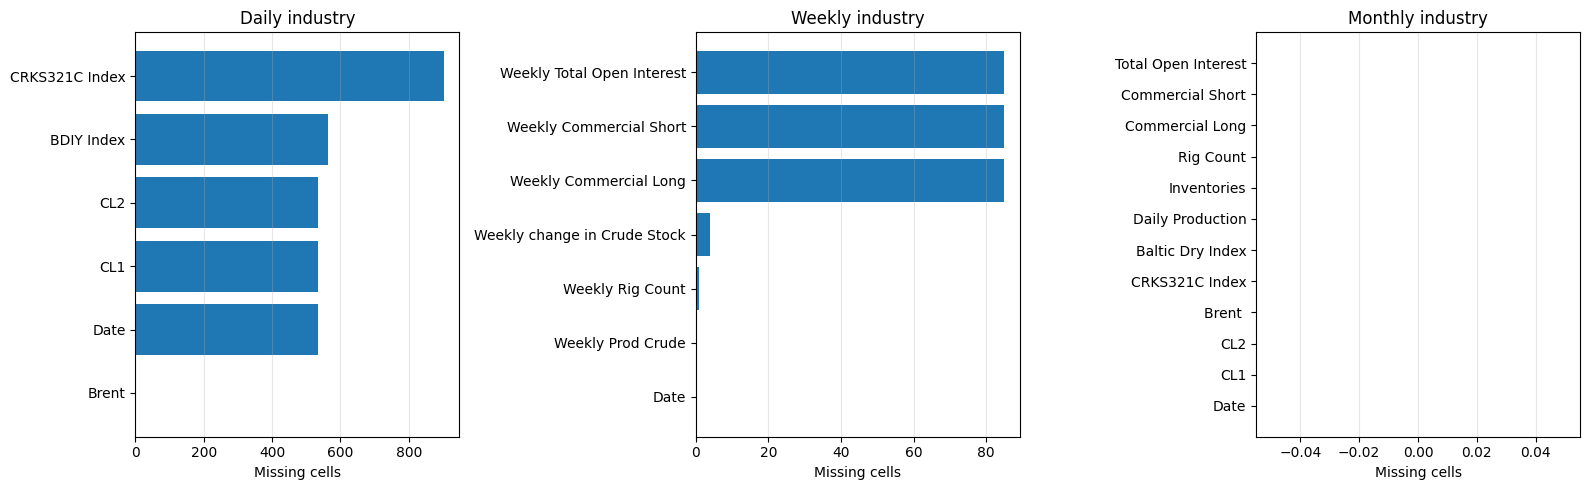

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, df, title in zip(
    axes,
    [daily, weekly, monthly_industry],
    ["Daily industry", "Weekly industry", "Monthly industry"],
):
    missing = df.isna().sum().sort_values()
    ax.barh(missing.index, missing.values)
    ax.set_title(title)
    ax.set_xlabel("Missing cells")
    ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
daily_dates = pd.to_datetime(daily["Date"], errors="coerce")
undated_daily = daily.loc[daily_dates.isna()]

print("Undated daily rows:", len(undated_daily))
display(undated_daily.head(10))

Undated daily rows: 534


,Date,CL1,CL2,Brent,CRKS321C Index,BDIY Index
8692,NaT,NaN,NaN,20.80,NaN,NaN
8693,NaT,NaN,NaN,19.84,NaN,NaN
8694,NaT,NaN,NaN,19.50,NaN,NaN
8695,NaT,NaN,NaN,19.22,NaN,NaN
8696,NaT,NaN,NaN,19.26,NaN,NaN
8697,NaT,NaN,NaN,19.18,NaN,NaN
8698,NaT,NaN,NaN,19.42,NaN,NaN
8699,NaT,NaN,NaN,19.22,NaN,NaN
8700,NaT,NaN,NaN,18.73,NaN,NaN
8701,NaT,NaN,NaN,18.59,NaN,NaN


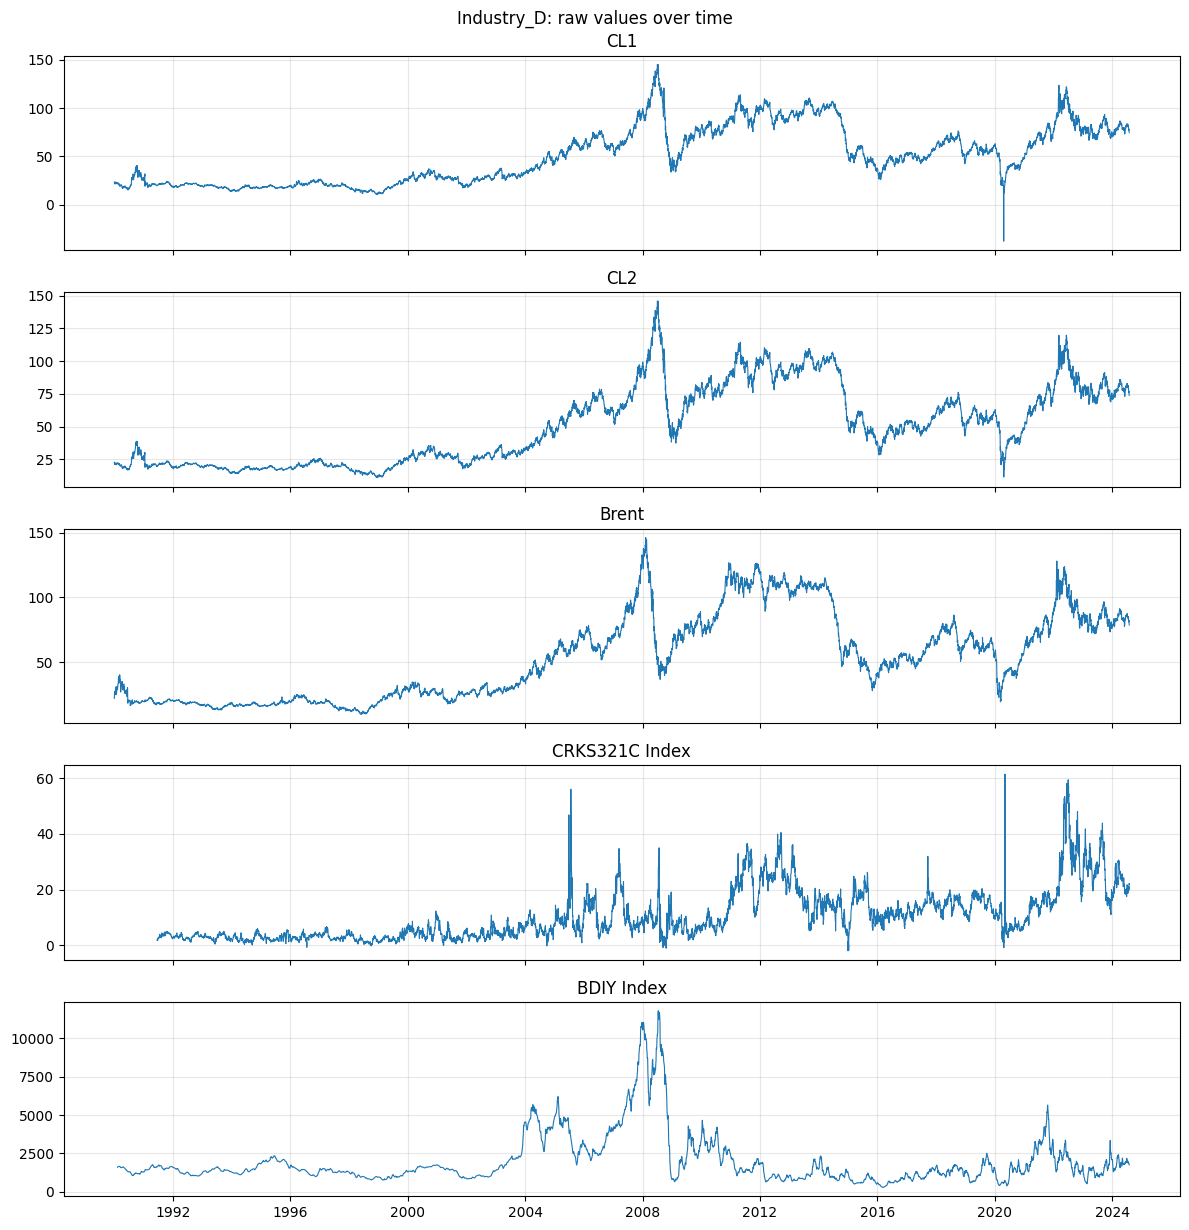

Rows in sheet: 9226; dated rows plotted: 8692


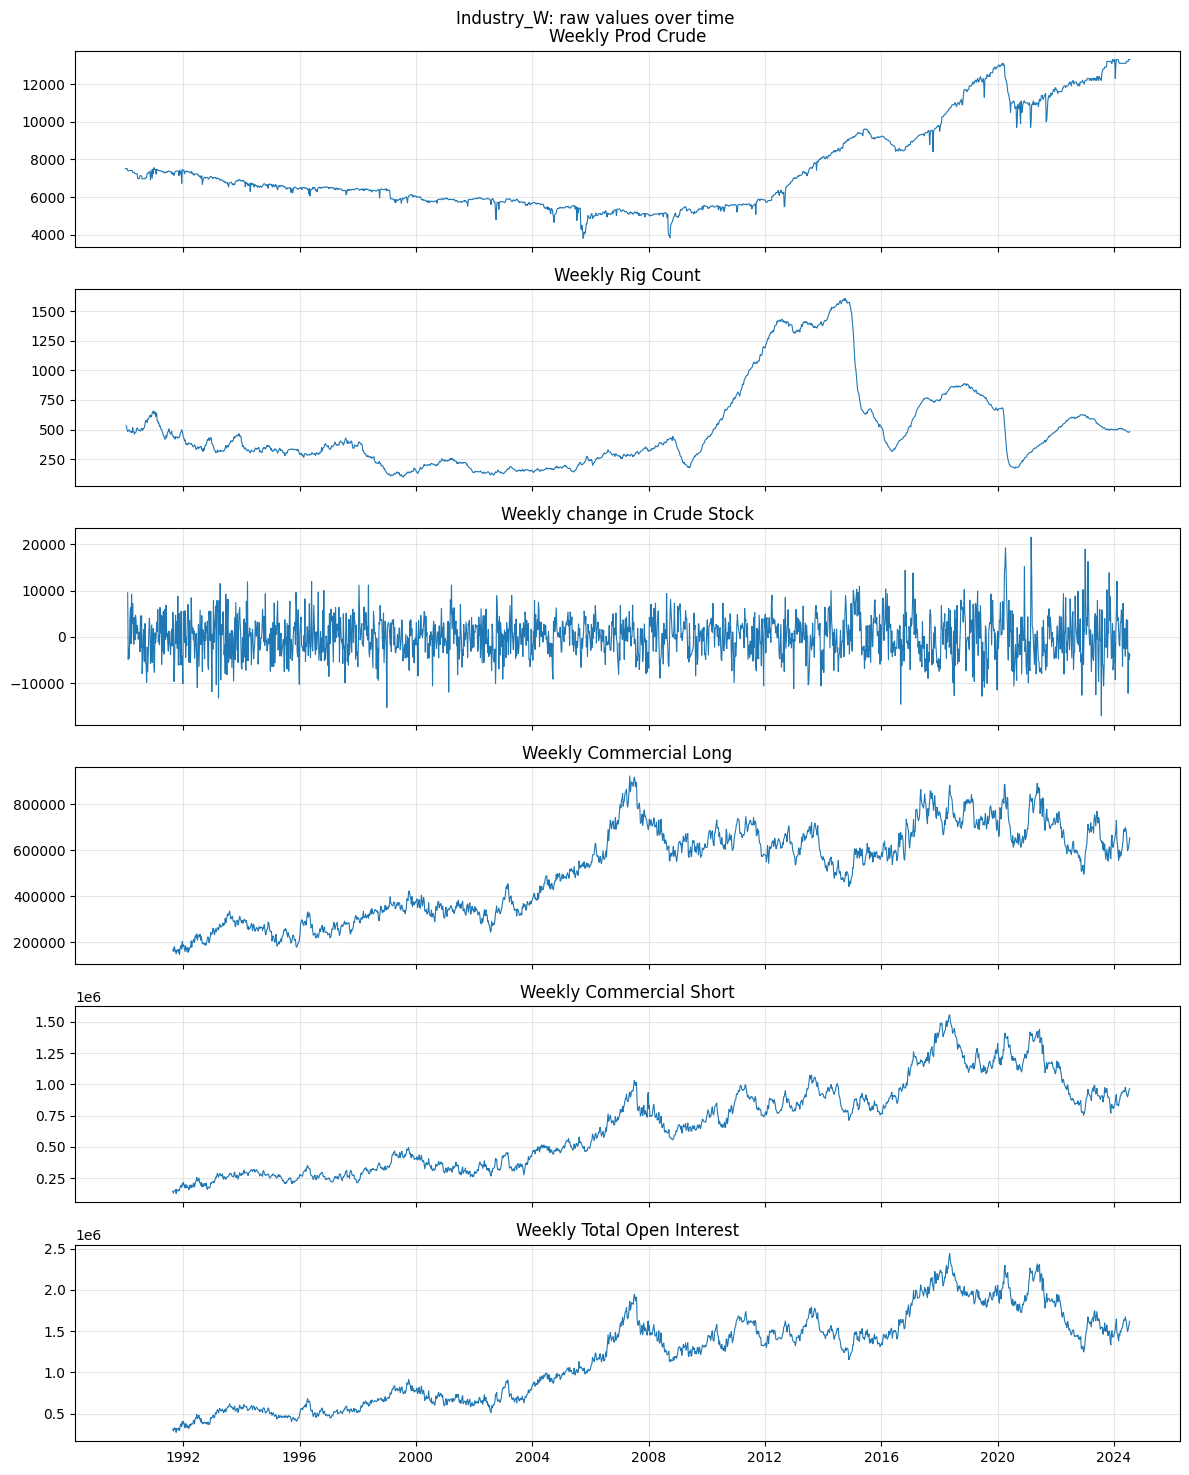

Rows in sheet: 1803; dated rows plotted: 1803


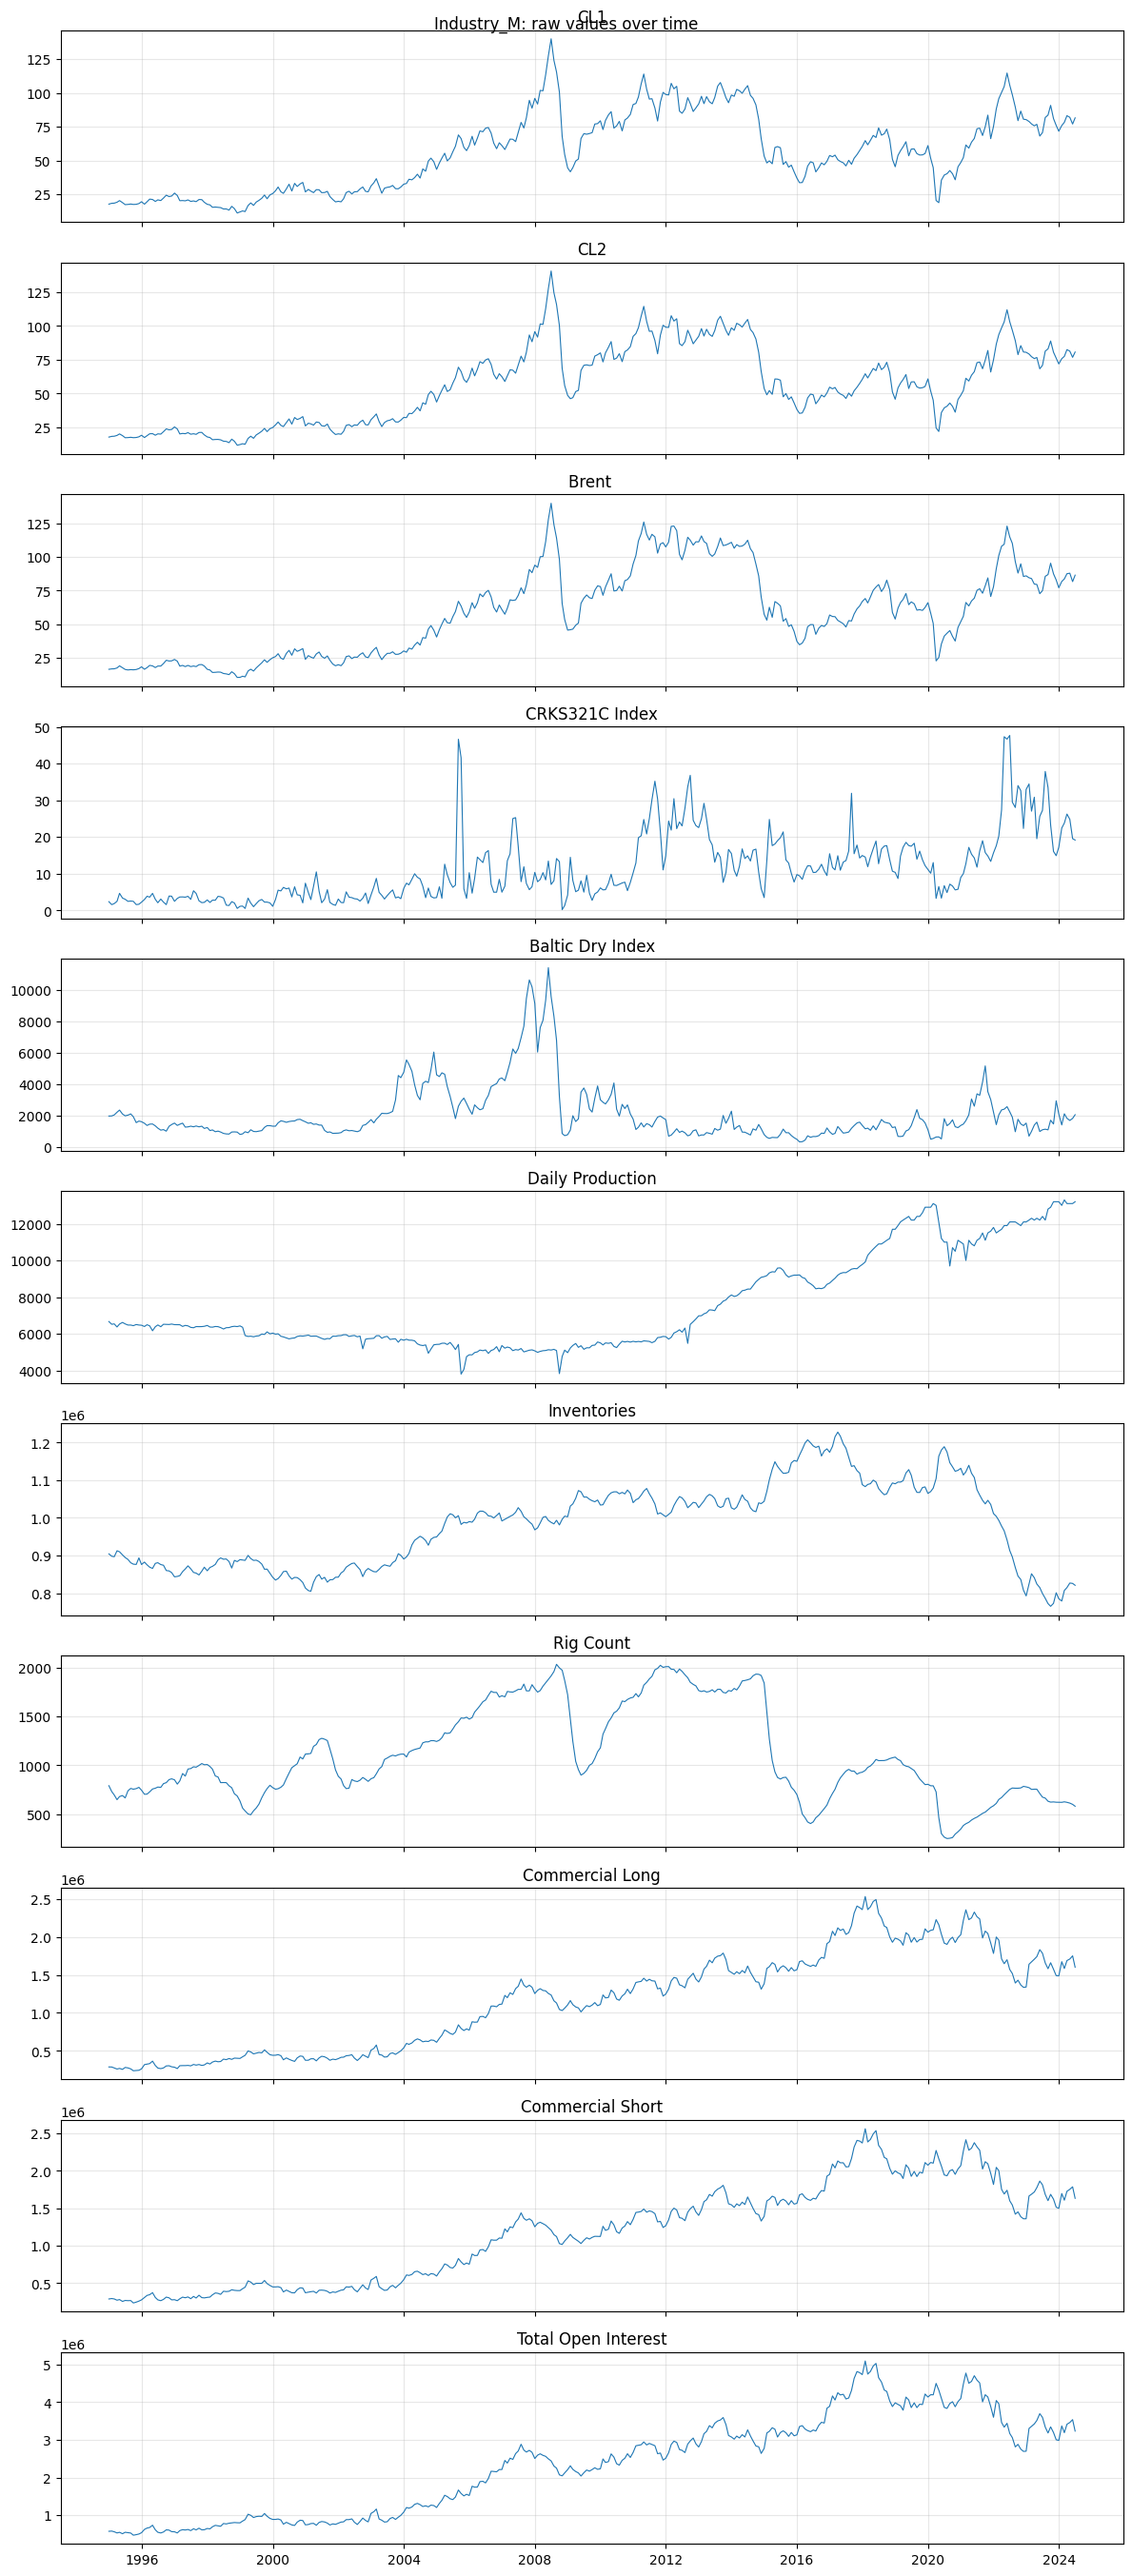

Rows in sheet: 355; dated rows plotted: 355


In [11]:
def plot_raw_sheet(df, sheet_name):
    plot_data = df.copy()
    plot_data["_plot_date"] = pd.to_datetime(
        plot_data["Date"], errors="coerce"
    )

    # Keep the original df intact; use only dated rows in this time-series view.
    dated = plot_data.loc[plot_data["_plot_date"].notna()].sort_values("_plot_date")
    numeric_columns = df.select_dtypes(include="number").columns

    fig, axes = plt.subplots(
        len(numeric_columns),
        1,
        figsize=(12, max(3, 2.5 * len(numeric_columns))),
        sharex=True,
        squeeze=False,
    )

    for ax, column in zip(axes[:, 0], numeric_columns):
        ax.plot(dated["_plot_date"], dated[column], linewidth=0.8)
        ax.set_title(column)
        ax.grid(True, alpha=0.3)

    fig.suptitle(f"{sheet_name}: raw values over time")
    fig.tight_layout()
    plt.show()

    print(f"Rows in sheet: {len(df)}; dated rows plotted: {len(dated)}")

plot_raw_sheet(daily, "Industry_D")
plot_raw_sheet(weekly, "Industry_W")
plot_raw_sheet(monthly_industry, "Industry_M")

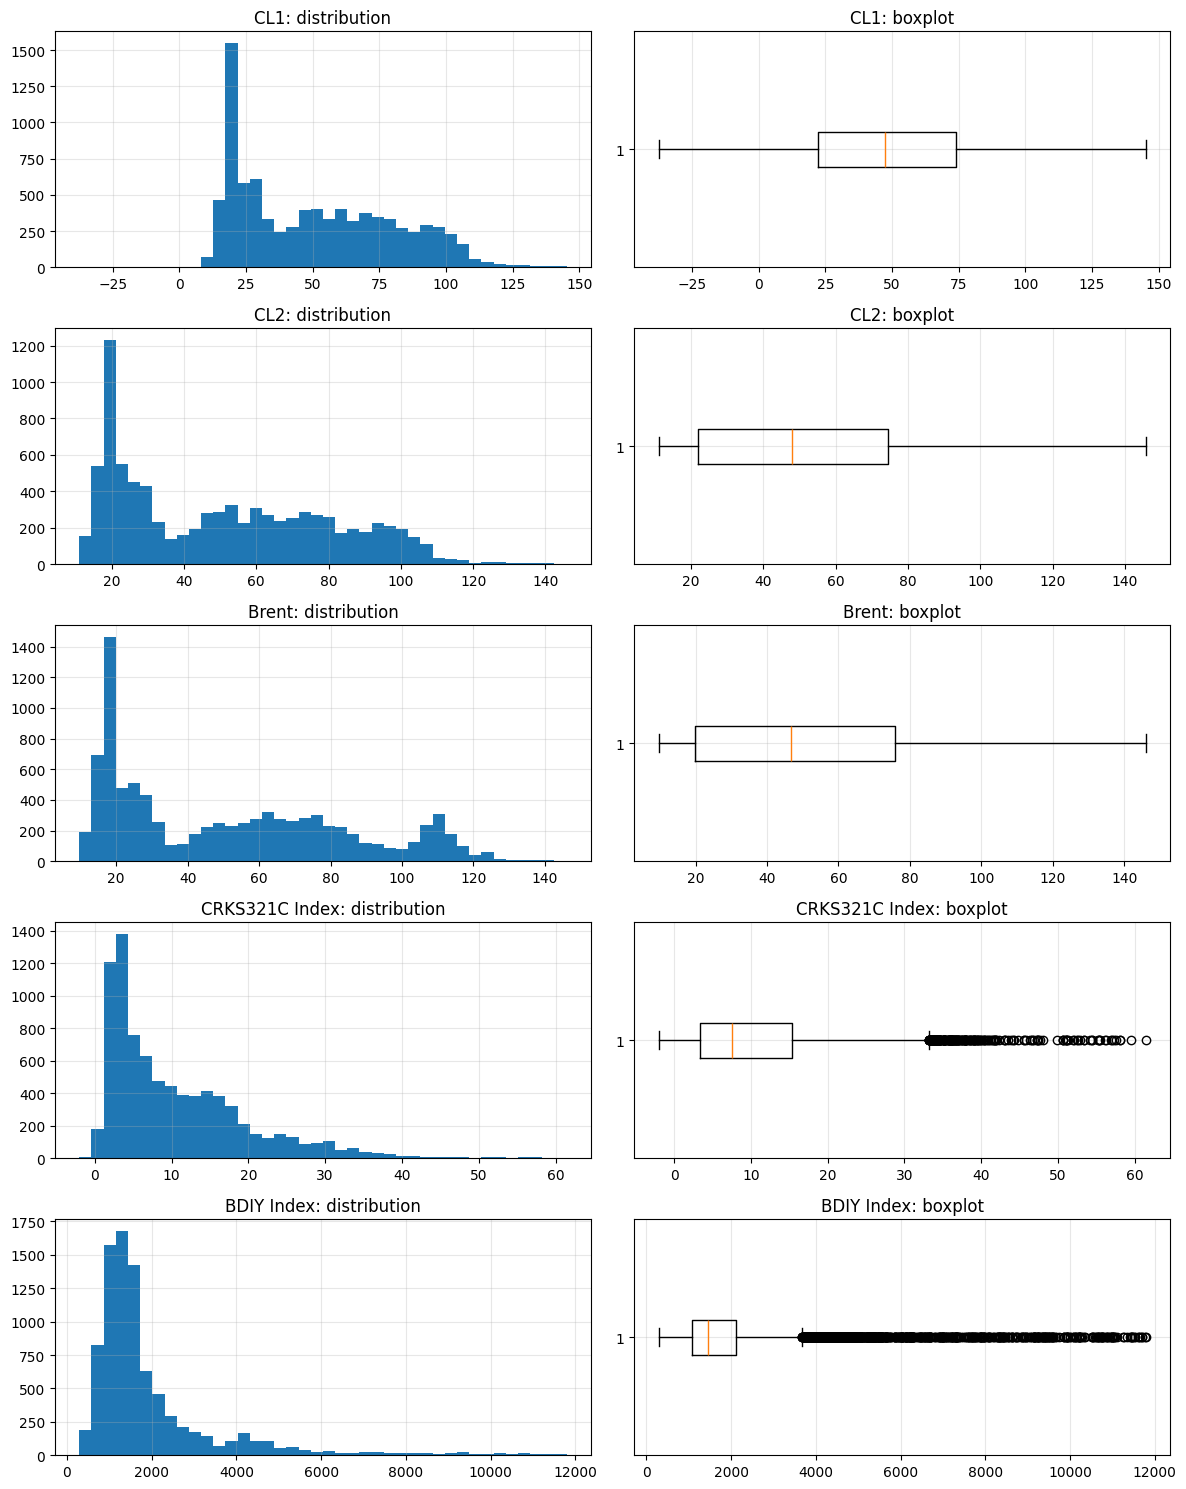

In [12]:
numeric = daily.select_dtypes(include="number")

fig, axes = plt.subplots(
    len(numeric.columns),
    2,
    figsize=(12, max(4, 3 * len(numeric.columns))),
)

for row, column in enumerate(numeric.columns):
    axes[row, 0].hist(numeric[column].dropna(), bins=40)
    axes[row, 0].set_title(f"{column}: distribution")
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].boxplot(numeric[column].dropna(), vert=False)
    axes[row, 1].set_title(f"{column}: boxplot")
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Exact dates present in both sheets: 341
Correlation: 0.914; fitted line: monthly = 0.926 × daily + 3.76


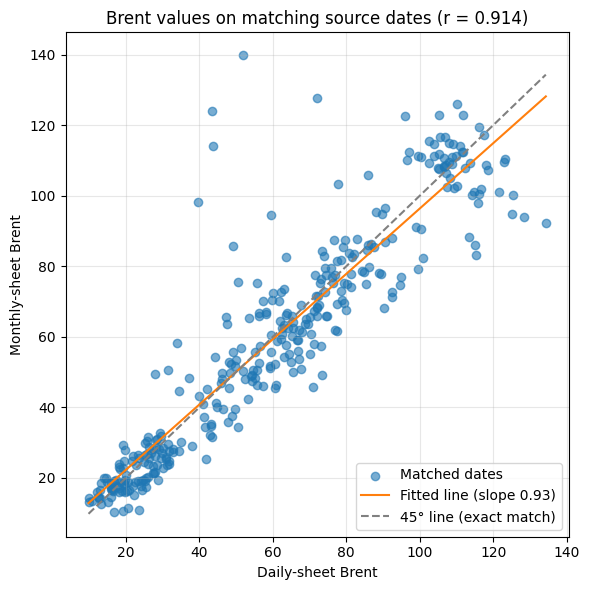

In [16]:
import numpy as np

daily_brent = daily[["Date", "Brent"]].copy()
monthly_brent = monthly_industry[["Date", "Brent "]].copy()

daily_brent["Date"] = pd.to_datetime(daily_brent["Date"], errors="coerce")
monthly_brent["Date"] = pd.to_datetime(monthly_brent["Date"], errors="coerce")

# Undated rows all become NaT, which would count as duplicate merge keys.
daily_brent = daily_brent.dropna(subset=["Date"])
monthly_brent = monthly_brent.dropna(subset=["Date"])

same_date = monthly_brent.merge(
    daily_brent,
    on="Date",
    how="inner",
    validate="one_to_one",
)

print("Exact dates present in both sheets:", len(same_date))

pairs = same_date[["Brent", "Brent "]].dropna()
x, y = pairs["Brent"], pairs["Brent "]
r = x.corr(y)
slope, intercept = np.polyfit(x, y, 1)
print(f"Correlation: {r:.3f}; fitted line: monthly = {slope:.3f} × daily + {intercept:.2f}")

line_x = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x, y, alpha=0.6, label="Matched dates")
ax.plot(line_x, slope * line_x + intercept, color="C1",
        label=f"Fitted line (slope {slope:.2f})")
ax.plot(line_x, line_x, color="grey", linestyle="--", label="45° line (exact match)")
ax.set_xlabel("Daily-sheet Brent")
ax.set_ylabel("Monthly-sheet Brent")
ax.set_title(f"Brent values on matching source dates (r = {r:.3f})")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
